# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Alen Anang Saputri
- **Email:** alensaputri272@gmail.com
- **ID Dicoding:** ds284b6x0131

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata konsentrasi PM2.5 pada 12 stasiun pemantauan kualitas udara di Beijing selama periode Maret 2013 hingga Februari 2017, dan stasiun mana yang perlu diprioritaskan dalam pemantauan kualitas udara?

- **Pertanyaan 2:** Bagaimana perubahan rata-rata konsentrasi PM2.5 dari bulan ke bulan selama periode Maret 2013 hingga Februari 2017, dan pada bulan apa konsentrasi PM2.5 cenderung paling tinggi?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import glob
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Data Wrangling

### Gathering Data

#### Load Dataset Air Quality

In [2]:
from google.colab import files

# Upload file ZIP
uploaded = files.upload()

# Mengambil nama file ZIP yang diunggah
zip_path = next(
    ("/content/" + name for name in uploaded.keys()
     if name.lower().endswith(".zip")),
    None
)

if zip_path is None:
    raise ValueError("Silakan unggah file dataset berformat ZIP.")

# Ekstraksi dataset
extract_path = "/content/air_quality"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Mencari seluruh file CSV
csv_files = glob.glob(
    os.path.join(extract_path, "**", "*.csv"),
    recursive=True
)

print("Jumlah file CSV:", len(csv_files))

if not csv_files:
    raise ValueError("Tidak ditemukan file CSV di dalam ZIP.")

# Membaca dan menggabungkan seluruh file CSV
dataframes = []

for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

print("Ukuran dataset:", df.shape)
print("Jumlah stasiun:", df["station"].nunique())

display(df.head())

Saving Air-quality-dataset.zip to Air-quality-dataset.zip
Jumlah file CSV: 12
Ukuran dataset: (420768, 18)
Jumlah stasiun: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,14.0,20.0,300.0,69.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Guanyuan
1,2,2013,3,1,1,4.0,4.0,13.0,17.0,300.0,72.0,-1.1,1023.2,-18.2,0.0,N,4.7,Guanyuan
2,3,2013,3,1,2,3.0,3.0,10.0,19.0,300.0,69.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Guanyuan
3,4,2013,3,1,3,3.0,6.0,7.0,24.0,400.0,62.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Guanyuan
4,5,2013,3,1,4,3.0,6.0,5.0,14.0,400.0,71.0,-2.0,1025.2,-19.5,0.0,N,2.0,Guanyuan


**Insight:** (Opsional)
- Dataset Air Quality terdiri dari 12 file CSV yang mewakili 12 stasiun pemantauan kualitas udara di Beijing. Seluruh file berhasil digabungkan menjadi satu DataFrame.
- Dataset gabungan memiliki 420.768 baris dan 18 kolom. Data ini mencakup pengamatan kualitas udara dan kondisi meteorologi berdasarkan waktu serta lokasi stasiun.

### Assessing Data

#### Identifying Data problem

In [3]:
# 1. Memeriksa informasi dataset
print("Informasi Dataset:")
df.info()

# 2. Memeriksa missing value
missing_data = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print("\nMissing Value:")
display(
    missing_data.sort_values(
        by="Jumlah Missing",
        ascending=False
    )
)

# 3. Memeriksa data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

# 4. Memeriksa jumlah data per stasiun
print("\nJumlah Data per Stasiun:")
display(df["station"].value_counts().sort_index())

# 5. Statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe().T)

# 6. Memeriksa komponen waktu
print("\nPemeriksaan Komponen Waktu:")
display(
    df[["year", "month", "day", "hour"]].describe().T
)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

Missing Value:


,Jumlah Missing,Persentase (%)
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09



Jumlah data duplikat: 0

Jumlah Data per Stasiun:


,count
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064



Statistik Deskriptif:


,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.500000,10122.116943,1.0000,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0



Pemeriksaan Komponen Waktu:


,count,mean,std,min,25%,50%,75%,max
year,420768.0,2014.662560,1.177198,2013.0,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0,5.75,11.5,17.25,23.0


**Steps to Take:**
- Memeriksa tipe data, jumlah baris dan kolom, serta kelengkapan nilai pada setiap kolom.
- Mengidentifikasi missing value pada variabel pengukuran kualitas udara dan kondisi meteorologi.
- Memeriksa kemungkinan baris duplikat dan kesesuaian jumlah observasi pada setiap stasiun.
- Memeriksa komponen waktu (tahun, bulan, hari, dan jam) untuk memastikan data dapat disusun menjadi informasi tanggal dan waktu.
- Mempertahankan nilai yang masih valid, termasuk nilai suhu dan titik embun negatif yang memang dapat terjadi secara alami.

**Insight:** (Opsional)
- Terdapat missing value pada beberapa kolom. Missing value terbanyak terdapat pada CO sebanyak 20.701 baris (4,92%), diikuti O3 sebanyak 13.277 baris (3,16%), NO2 sebanyak 12.116 baris (2,88%), dan PM2.5 sebanyak 8.739 baris (2,08%).
- Tidak ditemukan baris duplikat. Setiap stasiun memiliki 35.064 observasi, sehingga jumlah data pada 12 stasiun tercatat sama.
- Kolom tahun, bulan, hari, dan jam tersedia tanpa missing value. Komponen waktu masih terpisah sehingga perlu digabungkan menjadi satu kolom datetime untuk analisis berdasarkan waktu.

### Cleaning Data

#### Data Cleaning Process

In [4]:
# Membuat salinan agar data asli tetap aman
df_clean = df.copy()

# 1. Menghapus baris duplikat
df_clean = df_clean.drop_duplicates().copy()

# 2. Membuat kolom datetime
df_clean["datetime"] = pd.to_datetime(
    df_clean[["year", "month", "day", "hour"]],
    errors="coerce"
)

# 3. Menghapus tanggal yang tidak valid
invalid_datetime = df_clean["datetime"].isna().sum()
print("Tanggal tidak valid:", invalid_datetime)

df_clean = df_clean.dropna(
    subset=["datetime"]
).copy()

# 4. Menyiapkan data khusus untuk analisis PM2.5
missing_pm25 = df_clean["PM2.5"].isna().sum()

df_pm25 = df_clean.dropna(
    subset=["PM2.5"]
).copy()

# 5. Memeriksa hasil cleaning
print("\nJumlah data awal:", len(df))
print("Jumlah data setelah cleaning:", len(df_clean))
print("Missing value PM2.5 sebelum penanganan:", missing_pm25)
print("Jumlah data untuk analisis PM2.5:", len(df_pm25))
print("Missing value PM2.5 setelah penanganan:",
      df_pm25["PM2.5"].isna().sum())

display(df_clean.head())

Tanggal tidak valid: 0

Jumlah data awal: 420768
Jumlah data setelah cleaning: 420768
Missing value PM2.5 sebelum penanganan: 8739
Jumlah data untuk analisis PM2.5: 412029
Missing value PM2.5 setelah penanganan: 0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,14.0,20.0,300.0,69.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Guanyuan,2013-03-01 00:00:00
1,2,2013,3,1,1,4.0,4.0,13.0,17.0,300.0,72.0,-1.1,1023.2,-18.2,0.0,N,4.7,Guanyuan,2013-03-01 01:00:00
2,3,2013,3,1,2,3.0,3.0,10.0,19.0,300.0,69.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Guanyuan,2013-03-01 02:00:00
3,4,2013,3,1,3,3.0,6.0,7.0,24.0,400.0,62.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Guanyuan,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,6.0,5.0,14.0,400.0,71.0,-2.0,1025.2,-19.5,0.0,N,2.0,Guanyuan,2013-03-01 04:00:00


**Insight:** (Opsional)
- Tidak ditemukan baris duplikat dan tanggal tidak valid pada dataset, sehingga tidak ada baris yang terhapus karena kedua kondisi tersebut.
- Kolom datetime berhasil dibuat dari kolom tahun, bulan, hari, dan jam. Seluruh 420.768 baris tetap tersedia dalam df_clean.
- Terdapat 8.739 missing value pada PM2.5. Baris dengan PM2.5 kosong tidak disertakan dalam df_pm25, sehingga tersisa 412.029 observasi yang dapat digunakan untuk analisis PM2.5.
- Dataset df_clean tetap dipertahankan agar data pada kolom lain tidak ikut hilang hanya karena nilai PM2.5 kosong.

## Exploratory Data Analysis (EDA)

### Eksplorasi Konsentrasi PM2.5

In [5]:
# 1. Rata-rata PM2.5 per stasiun
station_pm25 = (
    df_pm25.groupby("station")["PM2.5"]
    .mean()
    .sort_values(ascending=False)
)

print("Rata-rata PM2.5 per Stasiun:")
display(station_pm25.reset_index())

print("Stasiun dengan rata-rata PM2.5 tertinggi:",
      station_pm25.idxmax())
print("Nilai rata-rata tertinggi:",
      round(station_pm25.max(), 2))

# 2. Rata-rata PM2.5 per bulan
monthly_pm25 = (
    df_pm25.groupby(
        df_pm25["datetime"].dt.to_period("M")
    )["PM2.5"]
    .mean()
)

monthly_pm25.index = monthly_pm25.index.to_timestamp()

print("\nRata-rata PM2.5 per Bulan:")
display(
    monthly_pm25.rename("Rata-rata PM2.5").reset_index()
)

print("Bulan dengan rata-rata PM2.5 tertinggi:",
      monthly_pm25.idxmax().strftime("%B %Y"))
print("Nilai rata-rata tertinggi per bulan:",
      round(monthly_pm25.max(), 2))

Rata-rata PM2.5 per Stasiun:


,station,PM2.5
0,Dongsi,86.194297
1,Wanshouxigong,85.024136
2,Nongzhanguan,84.838483
3,Gucheng,83.852089
4,Wanliu,83.374716
5,Guanyuan,82.933372
6,Aotizhongxin,82.773611
7,Tiantan,82.164911
8,Shunyi,79.491602
9,Changping,71.099743


Stasiun dengan rata-rata PM2.5 tertinggi: Dongsi
Nilai rata-rata tertinggi: 86.19

Rata-rata PM2.5 per Bulan:


,datetime,Rata-rata PM2.5
0,2013-03-01,104.888301
1,2013-04-01,62.139109
2,2013-05-01,81.846225
3,2013-06-01,102.444121
4,2013-07-01,67.909378
5,2013-08-01,60.628056
6,2013-09-01,76.123027
7,2013-10-01,91.990167
8,2013-11-01,73.890435
9,2013-12-01,78.452888


Bulan dengan rata-rata PM2.5 tertinggi: December 2015
Nilai rata-rata tertinggi per bulan: 150.52


**Insight:** (Opsional)
- Rata-rata PM2.5 tertinggi ditemukan di stasiun Dongsi, yaitu sekitar 86,19 µg/m³. Sementara itu, rata-rata terendah ditemukan di stasiun Dingling, yaitu sekitar 65,99 µg/m³.
- Perbedaan rata-rata antarstasiun menunjukkan bahwa konsentrasi PM2.5 yang tercatat tidak sama di seluruh lokasi pemantauan.
- Berdasarkan pengelompokan bulanan, rata-rata PM2.5 tertinggi terjadi pada Desember 2015 sebesar 150,52 µg/m³. Nilai terendah terjadi pada Februari 2016 sebesar 42,82 µg/m³.
- Hasil ini menunjukkan adanya perubahan konsentrasi PM2.5 dari bulan ke bulan. Namun, analisis ini bersifat deskriptif dan belum menjelaskan penyebab perubahan tersebut.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

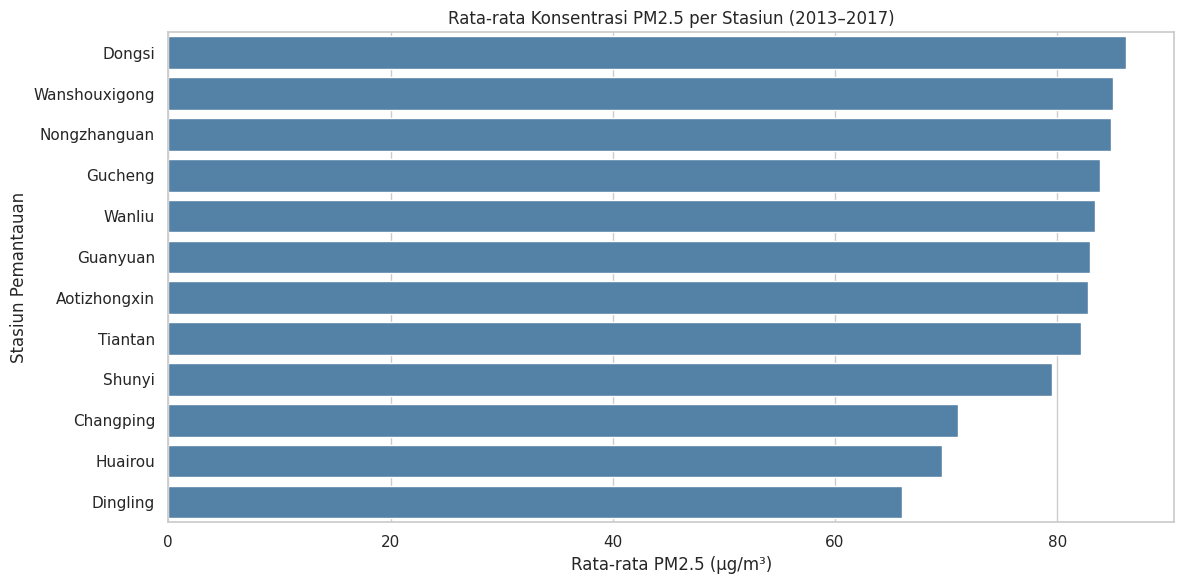

In [6]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=station_pm25.values,
    y=station_pm25.index,
    color="steelblue"
)

plt.title("Rata-rata Konsentrasi PM2.5 per Stasiun (2013–2017)")
plt.xlabel("Rata-rata PM2.5 (µg/m³)")
plt.ylabel("Stasiun Pemantauan")
plt.tight_layout()
plt.show()

### Pertanyaan 2:

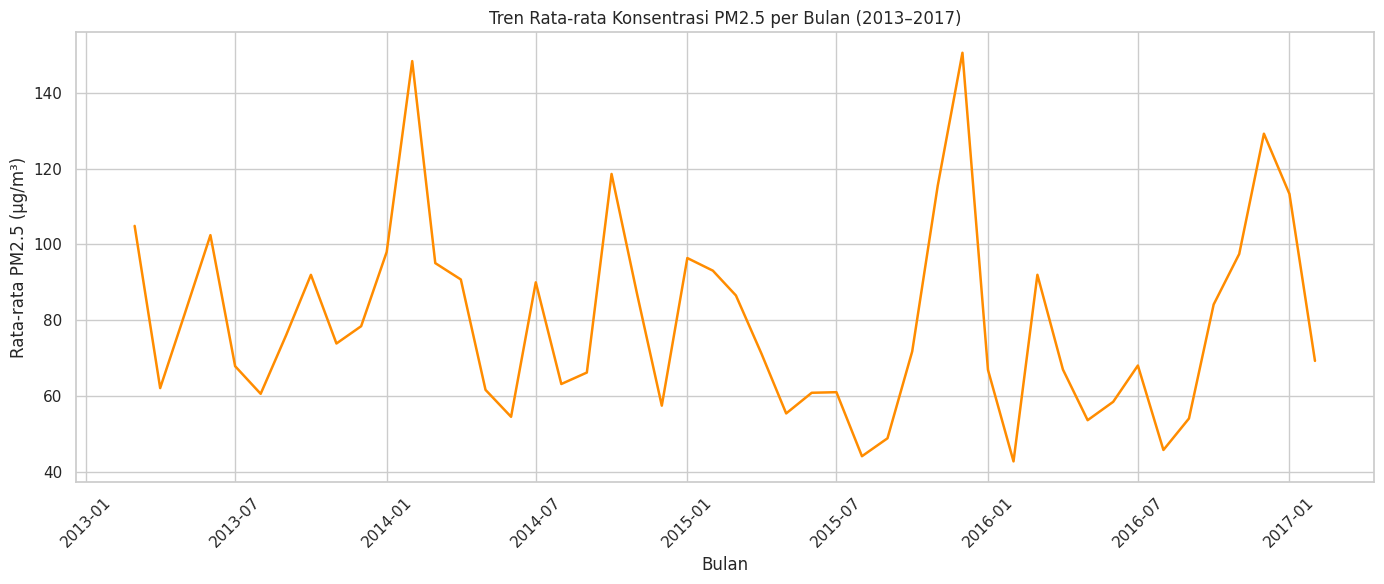

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_pm25.index,
    monthly_pm25.values,
    color="darkorange",
    linewidth=1.8
)

plt.title("Tren Rata-rata Konsentrasi PM2.5 per Bulan (2013–2017)")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik batang menunjukkan bahwa Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi di antara 12 stasiun, yaitu 86,19 µg/m³. Wanshouxigong dan Nongzhanguan juga memiliki rata-rata yang relatif tinggi, masing-masing sekitar 85,02 µg/m³ dan 84,84 µg/m³.
- Dingling memiliki rata-rata terendah, yaitu sekitar 65,99 µg/m³. Dengan demikian, terdapat perbedaan konsentrasi rata-rata PM2.5 antarstasiun selama periode pengamatan.
- Grafik garis memperlihatkan bahwa konsentrasi PM2.5 berfluktuasi dari bulan ke bulan, bukan meningkat atau menurun secara konsisten.
- Puncak rata-rata bulanan terjadi pada Desember 2015 sebesar 150,52 µg/m³. Rata-rata bulanan terendah terjadi pada Februari 2016 sebesar 42,82 µg/m³.

## Analisis Lanjutan (Opsional)

Jumlah Observasi per Kategori PM2.5:


,Kategori_PM25,Jumlah Observasi
0,Kuartil 1,103428
1,Kuartil 2,103689
2,Kuartil 3,102583
3,Kuartil 4,102329


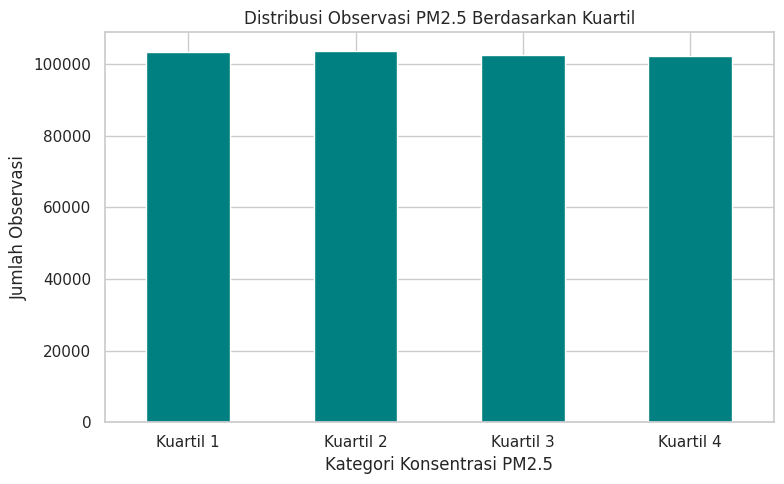

In [8]:
# Membagi konsentrasi PM2.5 menjadi empat kelompok berdasarkan kuartil
df_pm25["Kategori_PM25"] = pd.qcut(
    df_pm25["PM2.5"],
    q=4,
    labels=["Kuartil 1", "Kuartil 2", "Kuartil 3", "Kuartil 4"],
    duplicates="drop"
)

# Menghitung jumlah observasi dalam setiap kategori
kategori_counts = (
    df_pm25["Kategori_PM25"]
    .value_counts()
    .sort_index()
)

print("Jumlah Observasi per Kategori PM2.5:")
display(
    kategori_counts.rename("Jumlah Observasi").reset_index()
)

# Visualisasi distribusi kategori
kategori_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color="teal"
)

plt.title("Distribusi Observasi PM2.5 Berdasarkan Kuartil")
plt.xlabel("Kategori Konsentrasi PM2.5")
plt.ylabel("Jumlah Observasi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Observasi PM2.5 dibagi menjadi empat kelompok berdasarkan kuartil, yaitu Kuartil 1 hingga Kuartil 4. Pembagian ini membantu menggambarkan distribusi nilai PM2.5 dari kelompok relatif rendah hingga relatif tinggi.
- Jumlah observasi pada setiap kelompok relatif seimbang: Kuartil 1 sebanyak 103.428, Kuartil 2 sebanyak 103.689, Kuartil 3 sebanyak 102.583, dan Kuartil 4 sebanyak 102.329 observasi.
- Kategori kuartil merupakan pembagian berdasarkan distribusi data pada dataset, bukan kategori resmi indeks kualitas udara atau batas aman kesehatan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata konsentrasi PM2.5 berbeda antarstasiun pemantauan. Stasiun Dongsi memiliki rata-rata tertinggi sebesar 86,19 µg/m³, sedangkan Dingling memiliki rata-rata terendah sebesar 65,99 µg/m³. Berdasarkan hasil ini, Dongsi dapat menjadi salah satu prioritas pemantauan lebih lanjut karena mencatat rata-rata PM2.5 tertinggi selama periode pengamatan.
- **Conclusion pertanyaan 2:** Rata-rata konsentrasi PM2.5 mengalami fluktuasi dari bulan ke bulan selama Maret 2013 hingga Februari 2017. Rata-rata bulanan tertinggi tercatat pada Desember 2015 sebesar 150,52 µg/m³, sedangkan terendah pada Februari 2016 sebesar 42,82 µg/m³. Dengan demikian, konsentrasi PM2.5 tidak menunjukkan pola kenaikan atau penurunan yang konsisten sepanjang periode pengamatan.
- Conclusion analisis lanjutan: Pembagian berdasarkan kuartil menghasilkan jumlah observasi yang relatif seimbang pada empat kelompok. Analisis ini memberikan gambaran distribusi nilai PM2.5, tetapi tidak dapat digunakan sebagai pengganti kategori resmi kualitas udara.

**Rekomendasi Action Item:**
- Memprioritaskan pemantauan dan evaluasi lebih lanjut di stasiun Dongsi karena memiliki rata-rata konsentrasi PM2.5 tertinggi pada periode yang dianalisis.
- Memperhatikan perubahan konsentrasi PM2.5 secara berkala, terutama pada periode yang menunjukkan nilai rata-rata bulanan tinggi seperti Desember 2015.
- Melakukan pemeriksaan kualitas dan kelengkapan pencatatan data agar missing value pada pengukuran polutan dapat diminimalkan.
- Melakukan analisis lanjutan dengan mempertimbangkan faktor lain, seperti musim, kondisi meteorologi, dan aktivitas manusia, sebelum menyimpulkan penyebab tingginya konsentrasi PM2.5.

In [9]:
df.to_csv("main_data.csv", index=False)